# Module 10 · Thinking like an epidemiologist — uncertainty, comparison, survival and outbreaks
**BioCollaborator Health Informatics Programme** · Phase 3: Analytics · *Innovate Naturally*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BioCollaborator/ilanga-health-informatics/blob/main/notebooks/phase3_analytics/M10_epidemiology_biostatistics.ipynb)

> **File → Save a copy in Drive**, then run cells top to bottom with **Shift + Enter**.

In [1]:
# ⚙️ SETUP — run this cell first (click it, then press Shift + Enter)
import os, sys, subprocess

REPO_URL = "https://github.com/BioCollaborator/ilanga-health-informatics.git"

def _find_repo():
    for p in [".", "..", "../..", "ilanga-health-informatics"]:
        if os.path.exists(os.path.join(p, "ilanga", "__init__.py")):
            return os.path.abspath(p)
    return None

root = _find_repo()
if root is None:                                  # first run in Colab: fetch the course code
    subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    root = os.path.abspath("ilanga-health-informatics")
if root not in sys.path:
    sys.path.insert(0, root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ilanga

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BRAND = {"navy": "#0A2540", "ochre": "#C85A32", "teal": "#1A7A6E", "forest": "#14283E", "cream": "#F7F1E3"}
ilanga.hello()

✅ ilanga v1.0.0 ready  |  BioCollaborator Health Informatics  |  Innovate Naturally
   All data is synthetic. Ilanga District and Nqaba Health Informatics are fictional.


In [2]:
ilanga.brand.banner(10, "Thinking like an epidemiologist", "Phase 3 · Analytics", minutes=150)
ilanga.brand.ticket(
    "NQ-010", "Dr Musa Zungu", "District Epidemiologist, Ilanga District Health Services",
    "Build the district's epi toolkit - and run it on this week's surveillance data",
    "I keep seeing percentages in reports with no sense of how uncertain they are, and comparisons with no measure of "
    "effect. I'd like three reusable tools: a proper confidence interval, a risk ratio, and a weekly outbreak alert "
    "that finds real clusters without drowning my team in false alarms. Then run the alert on our diarrhoea "
    "surveillance data - something about KwaNtaba early this year is bothering me.",
    ["A Wilson 95% confidence interval function",
     "The TB risk ratio for people living with HIV compared with people without HIV",
     "A weekly outbreak alert list for 2025 that catches real clusters within 15 alerts",
     "A short epidemiological summary for the district management team"],
    priority="High - possible outbreak")

## Part 1 · Every estimate has uncertainty

"12 of 40 patients (30%) have uncontrolled blood pressure" sounds precise. But with only 40 patients, the true figure
could easily be 18% or 45%. A **confidence interval (CI)** shows that range.

The textbook formula — the **Wald interval**, `p ± 1.96 × √(p(1−p)/n)` — breaks down with small numbers or
proportions near 0% or 100%. Watch:

In [3]:
def wald_ci(k, n, z=1.96):
    p = k / n
    half = z * np.sqrt(p * (1 - p) / n)
    return (p - half, p + half)

for k, n in [(12, 40), (0, 25), (24, 25), (1, 8)]:
    lo, hi = wald_ci(k, n)
    print(f"{k:>3}/{n:<3} = {k/n:6.1%}   Wald 95% CI: {lo:7.1%} to {hi:7.1%}")

 12/40  =  30.0%   Wald 95% CI:   15.8% to   44.2%
  0/25  =   0.0%   Wald 95% CI:    0.0% to    0.0%
 24/25  =  96.0%   Wald 95% CI:   88.3% to  103.7%
  1/8   =  12.5%   Wald 95% CI:  -10.4% to   35.4%


Zero cases out of 25 gives a CI of **0% to 0%** — as if we were certain. And 1 out of 8 gives a *negative* lower
limit. Both are nonsense. The **Wilson score interval** fixes this, and is the standard choice for proportions in
health reporting.

### 🌱 Seedling — the Wilson interval
Write `wilson_ci(k, n, z=1.96)` returning `(lower, upper)` as **proportions** (0–1):

$$\text{centre} = \frac{p + \frac{z^2}{2n}}{1 + \frac{z^2}{n}} \qquad
\text{half-width} = \frac{z\sqrt{\frac{p(1-p)}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}}$$

Hints: `ilanga.hint("NQ-010.1")`.

In [4]:
def wilson_ci(k, n, z=1.96):
    # 👈 your code here
    return (None, None)

print(wilson_ci(12, 40), wilson_ci(0, 25))

(None, None) (None, None)


In [5]:
# Hypertension prevalence among adults, by sub-district, with Wilson CIs
d = ilanga.load_district()
p = d.patients.assign(age=ilanga.age_years(d.patients["date_of_birth"], ilanga.REFERENCE_DATE))
adults = p[p["age"] >= 18].copy()
adults["htn"] = adults["patient_id"].isin(d.conditions.loc[d.conditions["condition"] == "Hypertension", "patient_id"])

if wilson_ci(1, 2)[0] is not None:
    rows = []
    for sd, g in adults.groupby("subdistrict"):
        lo, hi = wilson_ci(g["htn"].sum(), len(g))
        rows.append({"subdistrict": sd, "n": len(g), "prevalence_%": 100 * g["htn"].mean(), "ci_low_%": 100 * lo, "ci_high_%": 100 * hi})
    prev = pd.DataFrame(rows).round(1)
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.errorbar(prev["subdistrict"], prev["prevalence_%"],
                yerr=[prev["prevalence_%"] - prev["ci_low_%"], prev["ci_high_%"] - prev["prevalence_%"]],
                fmt="o", color=BRAND["teal"], capsize=6)
    ax.set_ylabel("% of adults"); ax.set_title("Hypertension prevalence (registered adults), 95% CI")
    plt.show()
    display(prev)

⏳ Generating Ilanga District (first run in this session only, ~10 seconds)...


> 🩺 **Clinic Corner — overlapping intervals**
>
> If the CIs overlap a lot, you can't claim one sub-district is really different from another. Many "worst performing
> facility" league tables would disappear if they showed confidence intervals. Before you rank people, check
> whether the differences are bigger than the noise.

## Part 2 · Comparing groups: the risk ratio

People living with HIV are at much higher risk of TB. A **risk ratio (RR)** measures *how much* higher:

$$RR = \frac{\text{risk in exposed group}}{\text{risk in unexposed group}}$$

RR = 1 means no difference; RR = 3 means three times the risk.

### 🌿 Sapling — TB risk ratio
Using all **registered patients**: the exposed group is everyone with an HIV record, the unexposed group everyone
without. The outcome is having a TB record (a TB episode during 2024–2025). Store the ratio in `tb_rate_ratio`.
Hints: `ilanga.hint("NQ-010.2")`.

In [6]:
tb_rate_ratio = None   # 👈 your code here
tb_rate_ratio

In [7]:
# A 95% CI for the risk ratio, calculated on the log scale
if tb_rate_ratio:
    a, n1 = has_tb[exposed].sum(), exposed.sum()
    c, n0 = has_tb[~exposed].sum(), (~exposed).sum()
    se = np.sqrt(1/a - 1/n1 + 1/c - 1/n0)
    lo, hi = np.exp(np.log(tb_rate_ratio) - 1.96 * se), np.exp(np.log(tb_rate_ratio) + 1.96 * se)
    print(f"RR = {tb_rate_ratio:.2f} (95% CI {lo:.2f} to {hi:.2f})")

> 🤝 **Ubuntu Moment — association is not a sentence**
>
> A risk ratio describes groups, never individuals, and it isn't proof of cause. In Ilanga we *built* the link into
> the generator; in real data, other factors (poverty, crowding, age) get tangled in. Present comparisons carefully:
> a careless "people with HIV spread TB" headline does real harm to people already carrying stigma.

## Part 3 · Survival analysis: staying on treatment

"What percentage of people are still on ART after 12 months?" sounds simple — until you notice that someone who
started in November 2025 hasn't *had* 12 months yet. They're **censored**: we know they were retained *so far*, not
what happens next. The **Kaplan–Meier** method handles this properly.

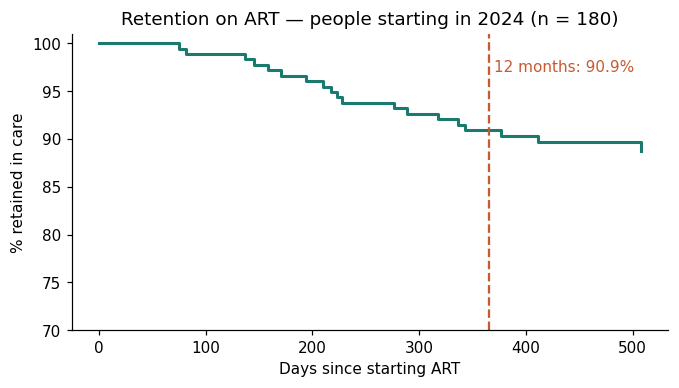

In [8]:
c = d.conditions[(d.conditions["condition"] == "HIV") & (d.conditions["art_start_date"].dt.year == 2024)].copy()
end = pd.Timestamp("2025-12-31")
c["event"] = c["status"].isin(["Lost to follow-up", "Died"])               # attrition from care
c["stop"] = np.where(c["status_date"].notna(), c["status_date"], end)       # transfers out are censored
c["days"] = (pd.to_datetime(c["stop"]) - c["art_start_date"]).dt.days.clip(lower=0)

def kaplan_meier(days, event):
    df = pd.DataFrame({"t": days, "e": event}).sort_values("t")
    at_risk, survival, rows = len(df), 1.0, [(0, 1.0)]
    for t, grp in df.groupby("t"):
        deaths = grp["e"].sum()
        if deaths:
            survival *= 1 - deaths / at_risk
            rows.append((t, survival))
        at_risk -= len(grp)
    return pd.DataFrame(rows, columns=["days", "retention"])

km = kaplan_meier(c["days"], c["event"])
r12 = km.loc[km["days"] <= 365, "retention"].iloc[-1]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.step(km["days"], km["retention"] * 100, where="post", color=BRAND["teal"], lw=2)
ax.axvline(365, ls="--", color=BRAND["ochre"]); ax.text(370, 97, f"12 months: {r12:.1%}", color=BRAND["ochre"])
ax.set_ylim(70, 101); ax.set_xlabel("Days since starting ART"); ax.set_ylabel("% retained in care")
ax.set_title(f"Retention on ART — people starting in 2024 (n = {len(c)})")
plt.show()

> 💻 **Code Corner — how Kaplan–Meier works**
>
> Walk forward through time. Each time someone leaves care, multiply the running retention by
> `1 − (people leaving ÷ people still being followed)`. Censored people simply drop out of the "still being
> followed" count — they never pretend to have left care. Libraries like `lifelines` do this for you, but it's
> worth knowing it's only a few lines of arithmetic.

## Part 4 · Outbreak detection in weekly surveillance

Every week, PHC facilities report counts of priority syndromes. The epidemiologist's question: **is this week
unusual for this facility?** Suspected outbreaks go to the district communicable disease control team, and
South Africa's **NICD** supports outbreak investigation and runs the notifiable medical conditions surveillance
system.

In [9]:
sv = d.weekly_surveillance
dia = sv[sv["syndrome"] == "Diarrhoea under 5"].sort_values(["facility_id", "week_start"]).copy()

fig, ax = plt.subplots(figsize=(10, 3.5))
for fid, g in dia.groupby("facility_id"):
    highlight = fid == "ILN-CL06"
    ax.plot(g["week_start"], g["cases"], lw=2 if highlight else 0.8,
            color=BRAND["ochre"] if highlight else "#9aa7b4", label="KwaNtaba Clinic" if highlight else None)
ax.set_title("Diarrhoea in under-5s, weekly cases per facility, 2023–2025"); ax.legend()
plt.show()

AttributeError: 'District' object has no attribute 'weekly_surveillance'

Notice two things: every facility has a **summer peak** (diarrhoea is seasonal), and facilities differ in size.
So "unusual" must be judged against **each facility's own recent history**.

A simple, widely taught approach compares each week with a **baseline** of earlier weeks:

- baseline = the mean and standard deviation of weeks *t−10* to *t−3* at the same facility
- the two most recent weeks are skipped (a **guard band**) so a growing outbreak doesn't raise its own baseline
- alert if `cases > baseline mean + z × baseline SD`

Here's the method on one facility with a sensitive threshold (z = 2):

In [ ]:
def add_alerts(df, z, lag=3, window=8):
    g = df.groupby("facility_id")["cases"]
    mean = g.transform(lambda x: x.shift(lag).rolling(window).mean())
    sd = g.transform(lambda x: x.shift(lag).rolling(window).std()).clip(lower=1)   # avoid SD = 0 in quiet clinics
    return df.assign(baseline=mean, threshold=mean + z * sd, alert=df["cases"] > mean + z * sd)

one = add_alerts(dia[dia["facility_id"] == "ILN-CHC01"], z=2)
one25 = one[one["iso_week"].str.startswith("2025")]
print(f"Lwandle CHC, z = 2: {one25['alert'].sum()} alerts in 2025 - with no real outbreak there.")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(one25["week_start"], one25["cases"], color=BRAND["navy"], label="cases")
ax.plot(one25["week_start"], one25["threshold"], color=BRAND["ochre"], ls="--", label="alert threshold")
ax.scatter(one25.loc[one25["alert"], "week_start"], one25.loc[one25["alert"], "cases"], color="red", zorder=3, label="alert")
ax.legend(); ax.set_title("A sensitive threshold raises false alarms"); plt.show()

### 🌳 Baobab — a district outbreak alert list for 2025
Build `outbreak_alerts`: a DataFrame with columns `facility_id` and `iso_week`, one row per **2025** alert for
*Diarrhoea under 5* across **all** facilities. Choose your threshold wisely:

- your alerts must catch a real cluster **within its first two weeks**, and
- the district team can handle **at most 15 alerts** a year — beyond that, people stop reading them.

Hints: `ilanga.hint("NQ-010.3")`.

In [ ]:
outbreak_alerts = pd.DataFrame(columns=["facility_id", "iso_week"])   # 👈 your code here

> 🩺 **Clinic Corner — an alert is a question, not an answer**
>
> An alert means *look closer*: call the clinic, check the register, ask about water supply, food events, a
> daycare. Four weeks of excess childhood diarrhoea at one rural clinic in summer could mean contaminated water after
> heavy rain. That's an environmental health and outbreak response trigger, and the reason early detection matters.

## 🚦 Quality gate

In [ ]:
passed = ilanga.tickets.check_nq010(wilson_ci, tb_rate_ratio, outbreak_alerts)

## 📝 Handover note — epidemiological summary
> **NQ-010 — done. For: Dr Musa Zungu.**
> *Toolkit: Wilson CIs, risk ratio with 95% CI, and a weekly alert rule (baseline weeks t−10 to t−3, z = …).*
> *Findings: TB risk is … times higher among people living with HIV (95% CI …). 12-month ART retention for the
> 2024 cohort is …%. The alert rule flagged … in 2025, including a cluster at … from week … .*
> *Recommended action: …*

## 🧭 Career Lens
**Epidemiologists**, **surveillance officers** and **biostatisticians** work at the NICD, provincial departments,
research units and universities. The Field Epidemiology Training Programme and MPH degrees are common routes in.
If you're a data person, epidemiology gives your numbers meaning; if you're a clinician, it's how you think about
populations instead of one patient at a time.

## 📚 Glossary
**Confidence interval** – range of plausible values for an estimate · **Wilson interval** – reliable CI for
proportions · **Risk ratio** – risk in one group divided by risk in another · **Censoring** – follow-up ended
without the event · **Kaplan–Meier** – survival estimate that handles censoring · **Baseline** – expected level
from history · **Guard band** – recent weeks excluded from the baseline · **Alert fatigue** – too many alarms, so
people ignore them all

## ✅ Checkpoint
<details><summary>1. Why is "0 of 25 = 0% (95% CI 0% to 0%)" wrong?</summary>With only 25 people, the true proportion could plausibly be as high as ~13%. The Wald formula collapses at 0; Wilson doesn't.</details>
<details><summary>2. Someone started ART two months ago. Why can't you count them as "retained at 12 months"?</summary>They haven't been followed for 12 months — they're censored. Kaplan–Meier uses their information only for the time actually observed.</details>
<details><summary>3. Why skip the two most recent weeks when building the baseline?</summary>So that the early weeks of an outbreak don't inflate the baseline and hide the outbreak.</details>

**Next up → Module 11:** Turning analysis into decisions: an emailable district dashboard and a map of who lives too
far from care.

---
<div align="center">

**BioCollaborator Health Informatics Programme** · *Innovate Naturally*<br>
Nqaba Health Informatics and Ilanga District are fictional. All data is synthetic.<br>
Questions and wins → the BioCollaborator **Health Career Hub** community.

</div>